<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES6_GAUSSIAN_MMIXTURE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**GAUSSIAN MIXTURE**

1) Load this file (`np.load`) and complete a quick exploration of the data. How many modes do you think you see?

<>:9: SyntaxWarning: invalid escape sequence '\o'
<>:9: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_845/2672028339.py:9: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel("Black hole mass $[M_\odot]$")


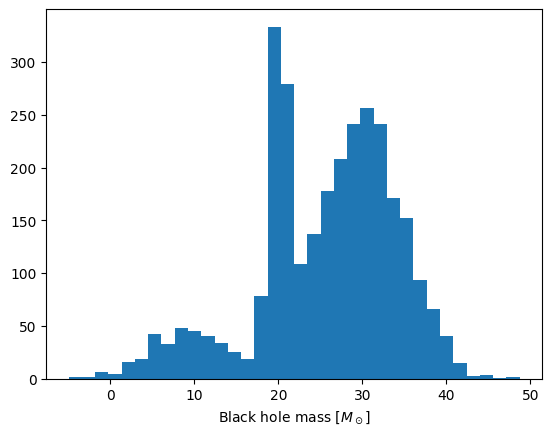


 3 Modes from visual analysis


In [20]:

import scipy as sc
import numpy as np
from matplotlib import pyplot as plt
import sklearn as skl

#data visualizzation
x=np.load('formationchannels.npy')
plt.hist(x[:,0],bins='auto')
plt.xlabel("Black hole mass $[M_\odot]$")

plt.show()

print('\n 3 Modes from visual analysis')

2. We'll use sklearn.mixture.GaussianMixture. You first need to define the model (instance of a class), and then train it on the data using the fit method (the data provided are already in the right numpy format!). This will output the trained model, which has various attributes.

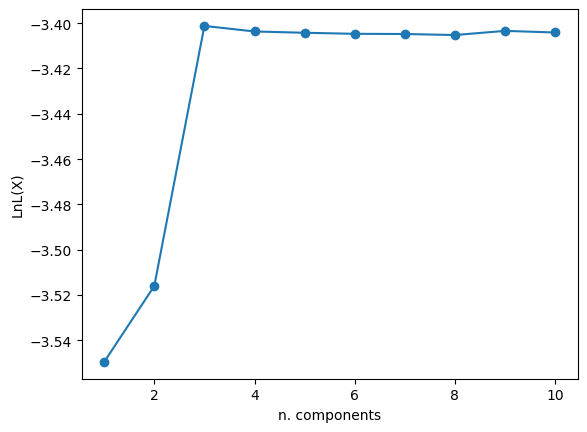


 The model with the best loglikelihood is the 3 modes model


In [21]:
#definisco e alleno il modello sui dati
gm = skl.mixture.GaussianMixture(n_components=3) #3 from visual guess
gm.fit(x)
gm.means_
gm.score(x) #loglikelihood

#computing loglikelihood for 0 to 10 modes
scores=[]
modes=np.linspace(1, 10, 10, dtype=int)
for i in (modes):
  gm = skl.mixture.GaussianMixture(n_components=i)
  gm.fit(x)
  scores.append(gm.score(x))

#plot
plt.plot(modes,scores)
plt.scatter(modes, scores)
plt.xlabel('n. components')
plt.ylabel('LnL(X)')
plt.show()

best_idx = np.argmax(scores)
best_mode = modes[best_idx]
print('\n The model with the best loglikelihood is the',best_mode, 'modes model')

4. For each of these fits, compute the AIC (easy! It's an attribute of the trained model!). Plot vs AIC: which model is preferred?

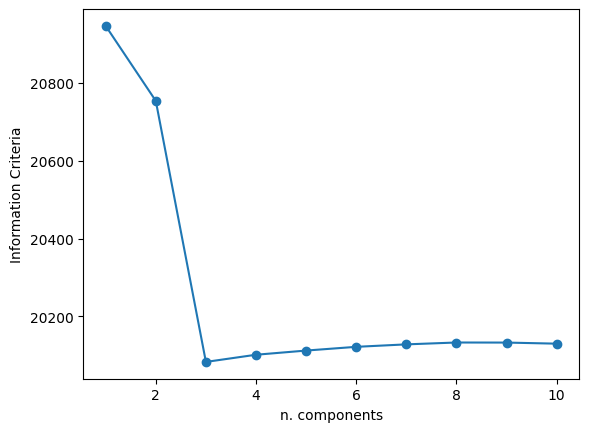


 The model with the best aic is the 3 modes model


In [22]:
aics=[]
for i in (modes):
  gm = skl.mixture.GaussianMixture(n_components=i)
  gm.fit(x)
  aics.append(gm.aic(x))

#plot
plt.plot(modes,aics)
plt.scatter(modes, aics)
plt.xlabel('n. components')
plt.ylabel('Information Criteria')
plt.show()

best_idx_aic = np.argmin(aics)
best_mode_aic = modes[best_idx]
print('\n The model with the best aic is the',best_mode_aic, 'modes model')


5. Plot the preferred solution on top of the input data. You should get a very nice fit!

<>:7: SyntaxWarning: invalid escape sequence '\o'
<>:7: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_845/2109298329.py:7: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel("Black hole mass $[M_\odot]$")


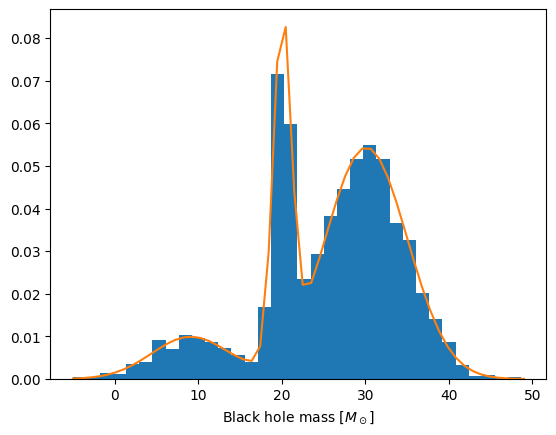

In [23]:
#plotting

x_fit=np.linspace(int(min(x[:,0])-1),int(max(x[:,0])+1),int(np.sqrt(len(x[:,0])))).reshape(-1,1)
gm = skl.mixture.GaussianMixture(n_components=best_mode_aic).fit(x)
plt.hist(x[:,0],bins='auto',density=True) #auto= sqrt(N of data) , density = True ->> normalizza l'istogramma
plt.plot(x_fit,np.exp(gm.score_samples(x_fit))) #returns the log-likelihood i need to exponenziate
plt.xlabel("Black hole mass $[M_\odot]$")
plt.show()